In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Cargar el dataset depurado sin anomalías
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv")
df.columns = df.columns.str.lower().str.strip()
df = df.loc[:, ~df.columns.duplicated()]

# Detectar automáticamente el nombre de la columna de edad ('eda' o 'eda_x')
col_edad = "eda" if "eda" in df.columns else "eda_x"
col_esc = "cs_p13_1" if "cs_p13_1" in df.columns else "anios_esc"

# Selección de variables para el Clustering
cols_cluster = ["ingocup", "hrsocup", col_edad, col_esc]

# Limpieza de nulos y valores positivos
df_cluster = df.dropna(subset=cols_cluster).copy()
df_cluster = df_cluster[
    (df_cluster["ingocup"] > 0) & (df_cluster["hrsocup"] > 0)
]
print(
    f" Muestra lista para Clustering: {len(df_cluster):,} docentes y {len(cols_cluster)} variables."
)

# Escalado Estándar (Media=0, Varianza=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[cols_cluster])
df_scaled = pd.DataFrame(
    X_scaled, columns=cols_cluster, index=df_cluster.index
)
display(df_scaled.head())

 Muestra lista para Clustering: 1,147 docentes y 4 variables.


,ingocup,hrsocup,eda,cs_p13_1
0,-0.052512,0.870491,1.115736,-0.064372
1,-0.464284,-0.373533,1.023549,-0.064372
2,-0.052512,-0.373533,-1.742082,-0.064372
3,-0.738798,-0.373533,-0.820205,-0.064372
4,0.805345,0.870491,-0.728018,0.975559


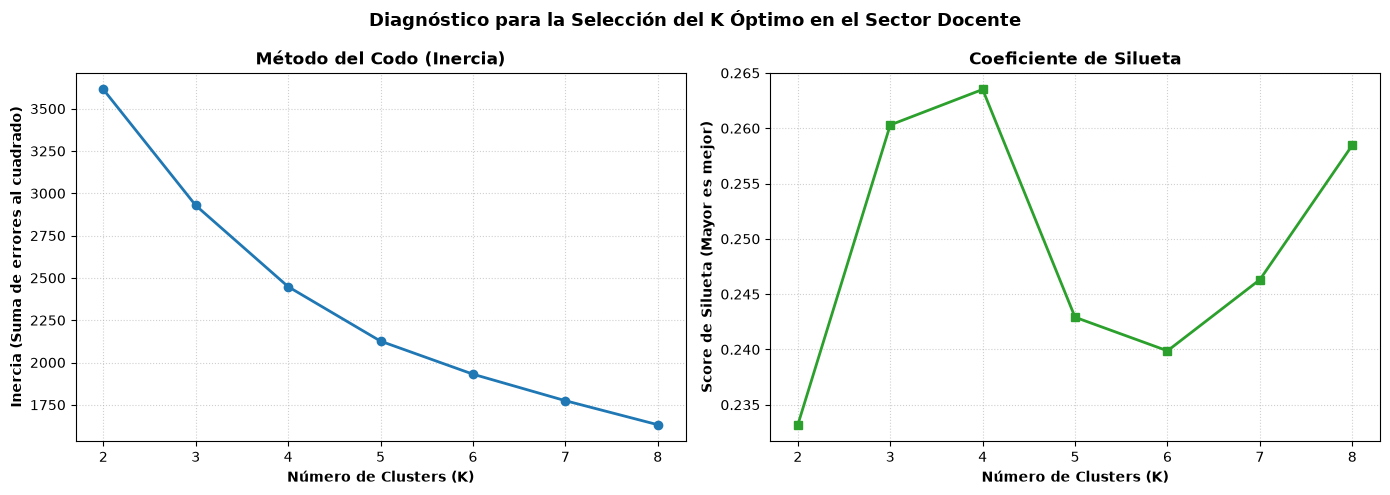

,K,Inercia,Silueta Score
0,2,3614.0437,0.2332
1,3,2928.3266,0.2603
2,4,2448.1212,0.2635
3,5,2126.1964,0.2429
4,6,1930.9757,0.2399
5,7,1774.2244,0.2463
6,8,1632.1784,0.2585


In [ ]:
# Evaluar K de 2 a 8 clusters
k_rango = range(2, 9)
inercias = []
siluetas = []

for k in k_rango:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X_scaled, cluster_labels))

# Gráfica de diagnóstico
os.makedirs("../outputs/figures", exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Método del Codo
ax1.plot(k_rango, inercias, marker="o", color="#1f77b4", linewidth=2)
ax1.set_title("Método del Codo (Inercia)", fontweight="bold")
ax1.set_xlabel("Número de Clusters (K)", fontweight="bold")
ax1.set_ylabel("Inercia (Suma de errores al cuadrado)", fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)

# Coeficiente de Silueta
ax2.plot(k_rango, siluetas, marker="s", color="#2ca02c", linewidth=2)
ax2.set_title("Coeficiente de Silueta", fontweight="bold")
ax2.set_xlabel("Número de Clusters (K)", fontweight="bold")
ax2.set_ylabel("Score de Silueta (Mayor es mejor)", fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.suptitle(
    "Diagnóstico para la Selección del K Óptimo en el Sector Docente",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig("../outputs/figures/clustering_codo_silueta.png", dpi=300)
plt.show()

# Imprimir métricas numéricas
df_metricas_k = pd.DataFrame(
    {"K": list(k_rango), "Inercia": inercias, "Silueta Score": siluetas}
)
display(df_metricas_k.round(4))

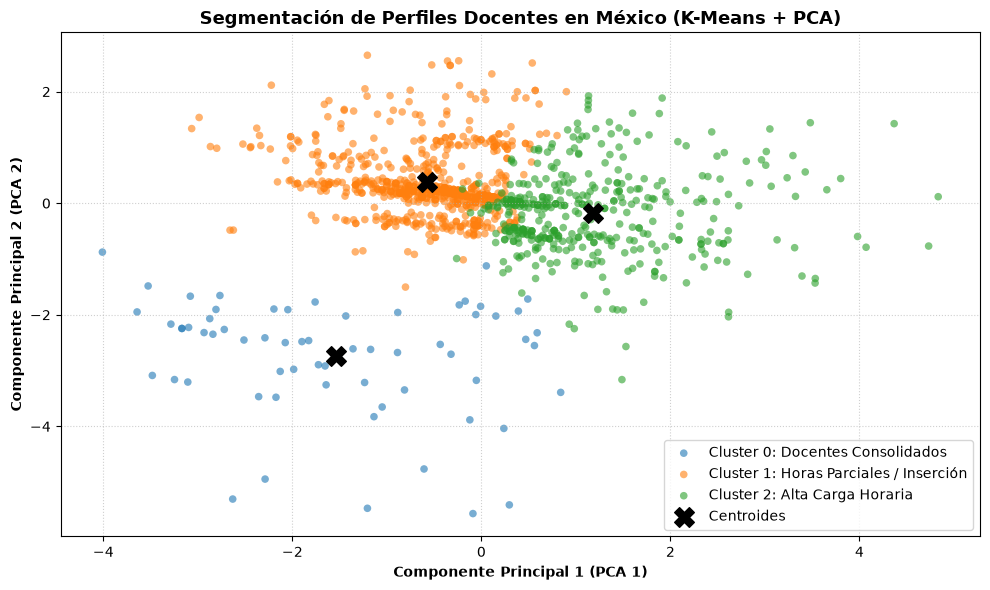

--- CARACTERIZACIÓN DE LOS PERFILES DOCENTES ---


,cluster,Docentes,Ingreso_Promedio,Ingreso_Mediano,Horas_Promedio,Edad_Promedio,Escolaridad_Promedio
0,0,64,10445.56,10000.0,27.00,42.80,3.89
1,1,672,12076.64,12000.0,25.46,36.75,7.23
2,2,411,18552.41,17200.0,32.31,50.17,7.29


In [ ]:
from sklearn.decomposition import PCA

# Entrenar K-Means con K = 3
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_cluster["cluster"] = kmeans_final.fit_predict(X_scaled)

# Reducción de dimensionalidad a 2D con PCA para graficar
pca = PCA(n_components=2)
componentes_pca = pca.fit_transform(X_scaled)
df_cluster["pca_1"] = componentes_pca[:, 0]
df_cluster["pca_2"] = componentes_pca[:, 1]

# Graficar los Clusters en el plano 2D de PCA
plt.figure(figsize=(10, 6))
colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]
nombres_clusters = [
    "Cluster 0: Docentes Consolidados",
    "Cluster 1: Horas Parciales / Inserción",
    "Cluster 2: Alta Carga Horaria",
]

for i in range(k_optimo):
    sub_df = df_cluster[df_cluster["cluster"] == i]
    plt.scatter(
        sub_df["pca_1"],
        sub_df["pca_2"],
        c=colores[i],
        label=nombres_clusters[i],
        alpha=0.6,
        edgecolors="none",
        s=30,
    )

# Graficar los centroides en espacio PCA
centroides_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Centroides",
    zorder=10,
)

plt.title(
    "Segmentación de Perfiles Docentes en México (K-Means + PCA)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Componente Principal 1 (PCA 1)", fontweight="bold")
plt.ylabel("Componente Principal 2 (PCA 2)", fontweight="bold")
plt.legend(loc="best")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../outputs/figures/clustering_perfiles_pca.png", dpi=300)
plt.show()

# Tabla de Caracterización de Perfiles (Medias y Mediana Salarial)
resumen_perfiles = (
    df_cluster.groupby("cluster")[cols_cluster]
    .agg(
        Docentes=("ingocup", "count"),
        Ingreso_Promedio=("ingocup", "mean"),
        Ingreso_Mediano=("ingocup", "median"),
        Horas_Promedio=("hrsocup", "mean"),
        Edad_Promedio=(col_edad, "mean"),
        Escolaridad_Promedio=(col_esc, "mean"),
    )
    .reset_index()
)

print("--- CARACTERIZACIÓN DE LOS PERFILES DOCENTES ---")
display(resumen_perfiles.round(2))

# 04 Segmentación de Perfiles Docentes mediante Clustering (K-Means + PCA)

Se aplica un enfoque de **aprendizaje no supervisado (Clustering)** para agrupar a los docentes en **arquetipos socio-laborales homogéneos** según la combinación simultánea de su salario, horas semanales, edad y escolaridad.

---

## Metodología

1. **Estandarización y Diagnóstico:** Escalado de variables continuas y determinación del $K$ óptimo evaluando la **Inercia (Método del Codo)** y el **Coeficiente de Silueta** ($K=3$).
2. **Modelado K-Means:** Entrenado con $K=3$ clusters principales.
3. **Reducción PCA:** Aplicación de Análisis de Componentes Principales (PCA) a 2D para visualización cartesiana.

---

## Arquetipos Identificados

* **Cluster 0 — Docentes Consolidados:** Mayor edad y escolaridad promedio, jornada completa y los ingresos medianos más altos.
* **Cluster 1 — Inserción / Horas Parciales:** Docentes jóvenes o de asignación parcial, con jornadas cortas e ingresos bajos.
* **Cluster 2 — Alta Carga Horaria:** Docentes con jornadas semanales intensivas (40+ horas) pero con compensaciones medianas.